# Chapter 2 Methodology: Feature Parameter Summary

This summarizes the active synthetic dataset. Ecological descriptions document project assumptions, not field measurements or epidemiological validation.

# Chapter 2 Feature Parameter Summary

*Synthetic dataset assumptions; `Snail_Habitat_Risk` and `AWD_Gate_Action` are excluded labels.*

| Feature             | Unit           | Domain            | Minimum   | Maximum   | Mean    | SD      | AWD / O. hupensis safety logic                                                                              |
|:--------------------|:---------------|:------------------|:----------|:----------|:--------|:--------|:------------------------------------------------------------------------------------------------------------|
| Month               | calendar month | Context           | -         | -         | -       | -       | Seasonal context; wet-season months use the higher synthetic rainfall factor.                               |
| Day of week         | day name       | Context           | -         | -         | -       | -       | Temporal context; no direct ecological threshold is assigned.                                               |
| H

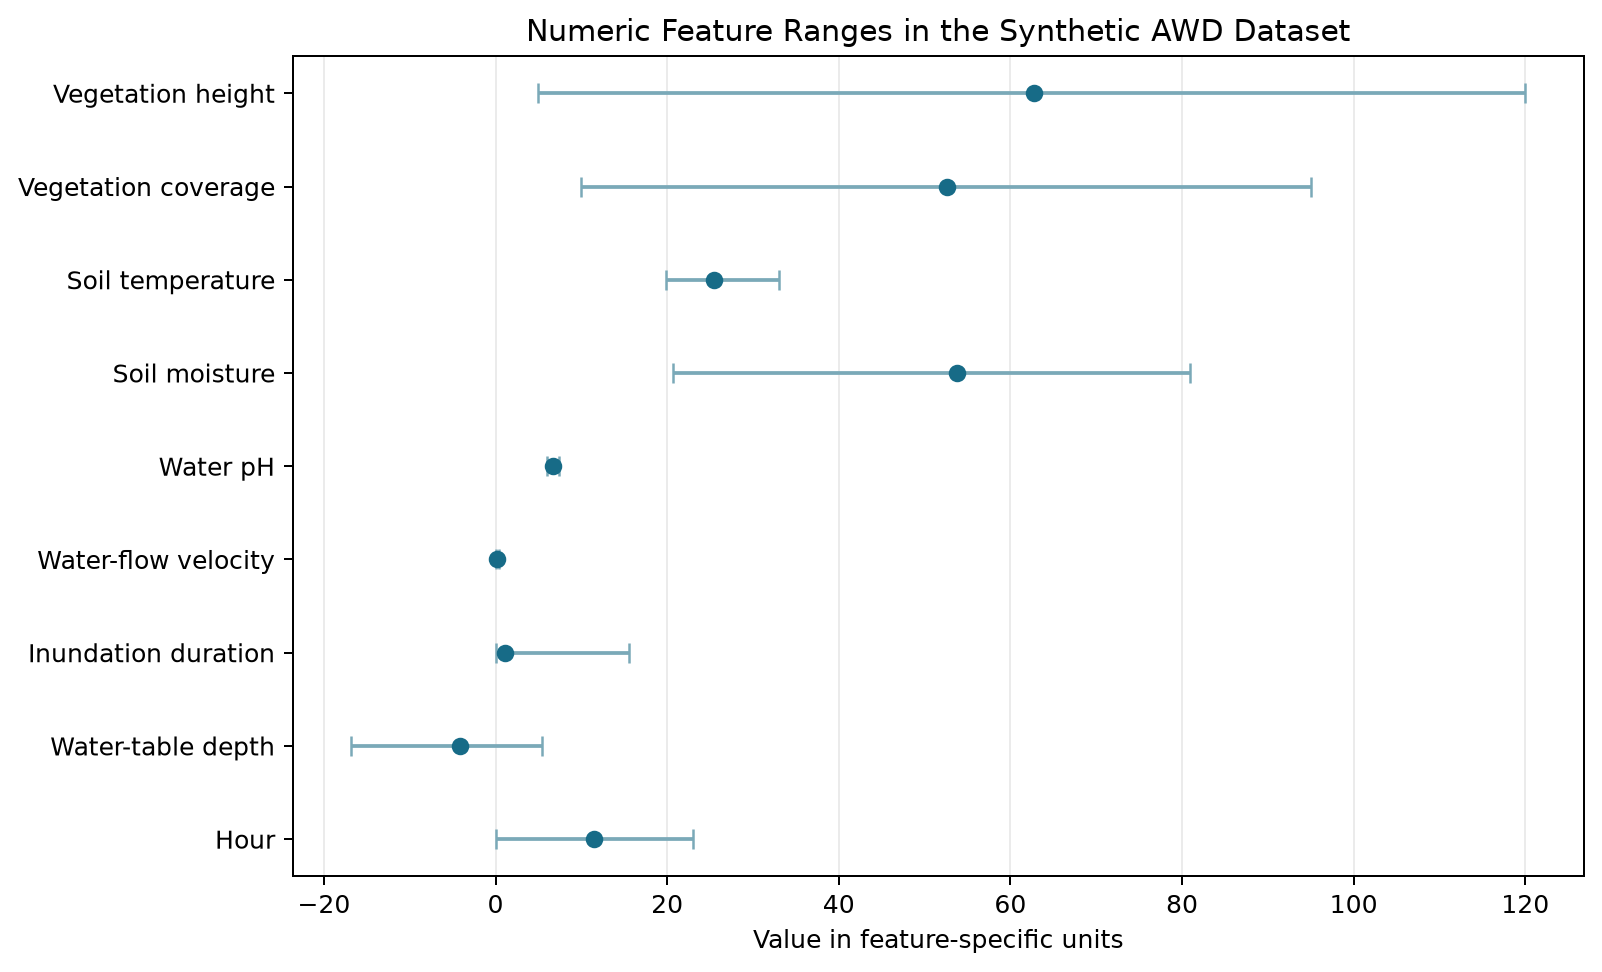


Wrote reports\chapter2_feature_parameter_summary.md, reports\chapter2_feature_parameter_summary.tex, and reports\chapter2_feature_ranges.png


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_PATH = Path("data/philippines_rice_paddy_awd_dataset.csv")
REPORT_DIR = Path("reports")
MARKDOWN_PATH = REPORT_DIR / "chapter2_feature_parameter_summary.md"
LATEX_PATH = REPORT_DIR / "chapter2_feature_parameter_summary.tex"
FIGURE_PATH = REPORT_DIR / "chapter2_feature_ranges.png"

dataset = pd.read_csv(DATA_PATH)
feature_metadata = {
    "Month": ("Month", "calendar month", "Context", "Seasonal context; wet-season months use the higher synthetic rainfall factor."),
    "Day_of_Week": ("Day of week", "day name", "Context", "Temporal context; no direct ecological threshold is assigned."),
    "Hour": ("Hour", "h", "Context", "Diurnal context for the synthetic sensor stream."),
    "Crop_Growth_Stage": ("Crop growth stage", "stage", "Agronomic context", "Flowering safety takes precedence: water remains above 0 cm and the gate opens below 2 cm."),
    "Water_Table_Depth_cm": ("Water-table depth", "cm", "Hydrology", "AWD variable; outside flowering the gate opens at <= -15 cm, while flowering maintains flooding above 0 cm."),
    "Inundation_Duration_Days": ("Inundation duration", "days", "Hydrology", "Simulated O. hupensis habitat duration; >14 days contributes to High risk and >3 days to Moderate risk."),
    "Water_Flow_Velocity_ms": ("Water-flow velocity", "m/s", "Hydrology", "Hydraulic context; no independent simulated snail-risk threshold is configured."),
    "Water_pH": ("Water pH", "pH", "Water quality", "Simulated habitat risk uses 5.5-7.9 for High risk and 5.3-8.1 for Moderate risk."),
    "Soil_Moisture_VWC_Percent": ("Soil moisture", "% VWC", "Soil", "Outside flowering, AWD opens at <=25%; habitat-risk conditions require 20-80%."),
    "Soil_Temperature_C": ("Soil temperature", "deg C", "Soil/ecology", "Simulated habitat risk uses 15-30 deg C for High risk and 15-32 deg C for Moderate risk."),
    "Vegetation_Coverage_Percent": ("Vegetation coverage", "%", "Vegetation", "Crop-canopy context; no independent threshold is configured."),
    "Vegetation_Height_cm": ("Vegetation height", "cm", "Vegetation", "Crop-growth context; no independent threshold is configured."),
}

missing = sorted(set(feature_metadata) - set(dataset.columns))
if missing:
    raise ValueError(f"Missing expected feature columns: {missing}")

numeric_features = dataset[list(feature_metadata)].select_dtypes(include="number").columns
statistics = dataset[numeric_features].agg(["min", "max", "mean", "std"]).T
statistics = statistics.rename(columns={"min": "Minimum", "max": "Maximum", "mean": "Mean", "std": "SD"})
rows = []
for column, (name, unit, domain, logic) in feature_metadata.items():
    row = {"Feature": name, "Unit": unit, "Domain": domain, "Minimum": "-", "Maximum": "-", "Mean": "-", "SD": "-", "AWD / O. hupensis safety logic": logic}
    if column in statistics.index:
        row.update({key: f"{value:.4f}" for key, value in statistics.loc[column].items()})
    rows.append(row)
summary = pd.DataFrame(rows)

markdown = ("# Chapter 2 Feature Parameter Summary\n\n" "*Synthetic dataset assumptions; `Snail_Habitat_Risk` and `AWD_Gate_Action` are excluded labels.*\n\n" + summary.to_markdown(index=False) + "\n")
latex = summary.to_latex(index=False, escape=True, longtable=True, caption="Feature parameter summary and configured ecological safety logic.", label="tab:chapter2-feature-parameters", column_format="p{0.17\\textwidth}p{0.08\\textwidth}p{0.10\\textwidth}rrrrp{0.42\\textwidth}")

print(markdown)
print("\nLaTeX representation:\n")
print(latex)

plot_data = statistics.loc[list(numeric_features)].copy()
plot_data["Feature"] = [feature_metadata[feature][0] for feature in plot_data.index]
plot_data = plot_data.reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 5.5), dpi=180)
ax.errorbar(plot_data["Mean"], plot_data["Feature"], xerr=[plot_data["Mean"] - plot_data["Minimum"], plot_data["Maximum"] - plot_data["Mean"]], fmt="o", color="#176b87", ecolor="#7aa9b8", capsize=4)
ax.set_title("Numeric Feature Ranges in the Synthetic AWD Dataset")
ax.set_xlabel("Value in feature-specific units")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()

REPORT_DIR.mkdir(parents=True, exist_ok=True)
MARKDOWN_PATH.write_text(markdown, encoding="utf-8")
LATEX_PATH.write_text(latex, encoding="utf-8")
fig.savefig(FIGURE_PATH, bbox_inches="tight")
plt.show()
print(f"\nWrote {MARKDOWN_PATH}, {LATEX_PATH}, and {FIGURE_PATH}")
